In [3]:
from pathlib import Path
from itertools import product
import json, time, gc
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree, ConvexHull
from scipy.interpolate import RBFInterpolator
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display

ROOT = Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/pareto")
PAIR_CONFIG = {
    "PairA": {
        "name": "E9.5_E1S1 -> E10.5_E2S1",
        "source": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_source_E9.5_E1S1.h5ad"),
        "target": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_target_E10.5_E2S1.h5ad"),
    },
    "PairC": {
        "name": "E10.5_E2S1 -> E11.5_E1S1",
        "source": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E10.5_E2S1.nbvae30.h5ad"),
        "target": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E11.5_E1S1.nbvae30.h5ad"),
    },
}
CURATED_PATH = Path("/mnt/disk2/lirui/baseline_scripts/mosta_flatvi_fgw/MOSTA_curated_transitions.tsv")
REP_KEY, SPATIAL_KEY, ANNOTATION_KEY = "X_nbvae_30", "spatial", "annotation"
LEIDEN_K, LEIDEN_SEED, LEIDEN_N_ITERATIONS = 15, 0, 2
SPATIAL_CC_FACTOR, N_BOUNDARY_POINTS = 1.5, 256
EVAL_DROP_LABELS = {"Cavity"}

def get_xy(adata):
    if SPATIAL_KEY not in adata.obsm: raise KeyError(f"{SPATIAL_KEY!r} missing")
    X = np.asarray(adata.obsm[SPATIAL_KEY], dtype=np.float64)
    if X.ndim != 2 or X.shape[1] < 2: raise ValueError(f"bad spatial shape={X.shape}")
    return X[:, :2]

def get_z(adata):
    if REP_KEY not in adata.obsm: raise KeyError(f"{REP_KEY!r} missing")
    Z = np.asarray(adata.obsm[REP_KEY], dtype=np.float32)
    if not np.isfinite(Z).all(): raise ValueError(f"non-finite {REP_KEY}")
    return Z

def run_leiden(adata, resolution):
    Z = get_z(adata)
    tmp = ad.AnnData(X=np.zeros((adata.n_obs, 1), dtype=np.float32))
    tmp.obsm["X_use"] = Z
    sc.pp.neighbors(tmp, use_rep="X_use", n_neighbors=min(LEIDEN_K, max(2, adata.n_obs - 1)), random_state=LEIDEN_SEED)
    sc.tl.leiden(tmp, resolution=float(resolution), key_added="leiden", random_state=LEIDEN_SEED, n_iterations=LEIDEN_N_ITERATIONS)
    return tmp.obs["leiden"].astype(str).to_numpy()

def median_1nn(xy):
    d, _ = cKDTree(xy).query(xy, k=2, workers=-1)
    d = d[:, 1]
    d = d[np.isfinite(d) & (d > 0)]
    if len(d) == 0: raise ValueError("cannot estimate median 1NN")
    return float(np.median(d))

def isotropic_normalize(X):
    X = np.asarray(X, dtype=np.float64)
    center = X.mean(axis=0)
    Xc = X - center
    scale = np.sqrt(np.mean(np.sum(Xc ** 2, axis=1)))
    if not np.isfinite(scale) or scale <= 0: raise ValueError("degenerate spatial scale")
    return Xc / scale, {"center": center, "scale": scale}

def pca_frame(X):
    cov = np.cov(np.asarray(X, dtype=np.float64).T)
    eigval, eigvec = np.linalg.eigh(cov)
    eigvec = eigvec[:, np.argsort(eigval)[::-1]]
    return np.asarray(X) @ eigvec, eigvec

def signed_permutation_matrices():
    mats = []
    for perm in [(0, 1), (1, 0)]:
        P = np.eye(2)[list(perm)]
        for sx, sy in product([-1.0, 1.0], repeat=2):
            mats.append(np.diag([sx, sy]) @ P)
    return mats

def convex_boundary(X):
    return np.asarray(X[ConvexHull(X).vertices], dtype=np.float64)

def resample_closed_curve(polygon, n_points):
    polygon = np.asarray(polygon, dtype=np.float64)
    closed = np.vstack([polygon, polygon[0]])
    delta = np.diff(closed, axis=0)
    seglen = np.linalg.norm(delta, axis=1)
    good = seglen > 1e-12
    if not np.all(good):
        closed = closed[np.r_[good, True]]
        delta = np.diff(closed, axis=0)
        seglen = np.linalg.norm(delta, axis=1)
    cumulative = np.r_[0.0, np.cumsum(seglen)]
    total = cumulative[-1]
    query = np.linspace(0.0, total, int(n_points), endpoint=False)
    out = []
    for s in query:
        j = np.searchsorted(cumulative, s, side="right") - 1
        j = min(max(j, 0), len(seglen) - 1)
        u = (s - cumulative[j]) / seglen[j]
        out.append((1.0 - u) * closed[j] + u * closed[j + 1])
    return np.asarray(out)

def boundary_sample(X, n_points=N_BOUNDARY_POINTS):
    return resample_closed_curve(convex_boundary(X), n_points)

def symmetric_chamfer(A, B):
    tree_A, tree_B = cKDTree(A), cKDTree(B)
    d_AB, _ = tree_B.query(A, k=1, workers=-1)
    d_BA, _ = tree_A.query(B, k=1, workers=-1)
    return float(0.5 * (np.mean(d_AB ** 2) + np.mean(d_BA ** 2)))

def choose_orientation(src_pca, tgt_pca):
    tgt_boundary = boundary_sample(tgt_pca)
    best = None
    for M in signed_permutation_matrices():
        src_try = src_pca @ M.T
        src_boundary = boundary_sample(src_try)
        score = symmetric_chamfer(src_boundary, tgt_boundary)
        if best is None or score < best["score"]:
            best = {"score": score, "matrix": M.copy(), "src_aligned": src_try, "src_boundary": src_boundary}
    return best, tgt_boundary

def cyclic_boundary_match(source_boundary, target_boundary):
    if len(source_boundary) != len(target_boundary): raise ValueError("boundary sample sizes differ")
    best_score, best_shift, best_target = np.inf, None, None
    for shift in range(len(source_boundary)):
        Y = np.roll(target_boundary, shift, axis=0)
        score = float(np.mean(np.sum((source_boundary - Y) ** 2, axis=1)))
        if score < best_score:
            best_score, best_shift, best_target = score, shift, Y
    return best_target, int(best_shift), float(best_score)

def fit_bidirectional_tps(source_boundary, target_boundary):
    forward = RBFInterpolator(source_boundary, target_boundary, kernel="thin_plate_spline", smoothing=0.0, degree=1)
    backward = RBFInterpolator(target_boundary, source_boundary, kernel="thin_plate_spline", smoothing=0.0, degree=1)
    return forward, backward

def build_global_deformation(src_xy_raw, tgt_xy_raw):
    src_iso, src_iso_meta = isotropic_normalize(src_xy_raw)
    tgt_iso, tgt_iso_meta = isotropic_normalize(tgt_xy_raw)
    src_pca, src_basis = pca_frame(src_iso)
    tgt_pca, tgt_basis = pca_frame(tgt_iso)
    orientation, tgt_boundary = choose_orientation(src_pca, tgt_pca)
    src_aligned, src_boundary = orientation["src_aligned"], orientation["src_boundary"]
    tgt_boundary_matched, cyclic_shift, cyclic_mse = cyclic_boundary_match(src_boundary, tgt_boundary)
    forward_tps, backward_tps = fit_bidirectional_tps(src_boundary, tgt_boundary_matched)
    warped_source = np.asarray(forward_tps(src_aligned), dtype=np.float64)
    reconstructed_source = np.asarray(backward_tps(warped_source), dtype=np.float64)
    cycle_error = np.linalg.norm(reconstructed_source - src_aligned, axis=1)
    return {
        "source_aligned": src_aligned, "target_aligned": tgt_pca, "warped_source": warped_source,
        "cycle_error": cycle_error, "orientation_matrix": orientation["matrix"],
        "orientation_score": orientation["score"], "cyclic_shift": cyclic_shift, "cyclic_mse": cyclic_mse,
        "source_boundary": src_boundary, "target_boundary": tgt_boundary_matched,
        "source_iso_meta": src_iso_meta, "target_iso_meta": tgt_iso_meta,
        "source_pca_basis": src_basis, "target_pca_basis": tgt_basis,
    }

def query_pairs_array(tree, radius):
    try:
        pairs = tree.query_pairs(radius, output_type="ndarray")
        return np.asarray(pairs, dtype=np.int64).reshape(-1, 2)
    except TypeError:
        pairs = list(tree.query_pairs(radius))
        return np.empty((0, 2), dtype=np.int64) if not pairs else np.asarray(pairs, dtype=np.int64)

def leiden_spatial_components(labels, xy, radius):
    labels = np.asarray(labels, dtype=str)
    piece_of_spot = np.full(len(labels), -1, dtype=np.int32)
    pieces, piece_leiden = [], []
    for lab in pd.unique(labels):
        idx = np.flatnonzero(labels == lab)
        if len(idx) == 1:
            cid = len(pieces); pieces.append(idx.astype(np.int32)); piece_leiden.append(str(lab)); piece_of_spot[idx] = cid; continue
        pairs = query_pairs_array(cKDTree(xy[idx]), radius)
        if len(pairs):
            rows, cols = np.r_[pairs[:, 0], pairs[:, 1]], np.r_[pairs[:, 1], pairs[:, 0]]
            graph = csr_matrix((np.ones(len(rows), dtype=np.uint8), (rows, cols)), shape=(len(idx), len(idx)))
        else:
            graph = csr_matrix((len(idx), len(idx)), dtype=np.uint8)
        n_comp, cc = connected_components(graph, directed=False, return_labels=True)
        for local_c in range(n_comp):
            spots = idx[cc == local_c]
            cid = len(pieces); pieces.append(spots.astype(np.int32)); piece_leiden.append(str(lab)); piece_of_spot[spots] = cid
    if np.any(piece_of_spot < 0): raise RuntimeError("some spots lack component assignment")
    return {"pieces": pieces, "piece_of_spot": piece_of_spot, "piece_leiden": np.asarray(piece_leiden, dtype=str)}

def domain_geometry_cost(X, Y):
    d_xy, _ = cKDTree(Y).query(X, k=1, workers=-1)
    d_yx, _ = cKDTree(X).query(Y, k=1, workers=-1)
    return float(0.5 * (np.median(d_xy) + np.median(d_yx)))

def pareto_front_2d(E, G):
    front = np.ones(E.shape[0], dtype=bool)
    for j in range(E.shape[0]):
        dominated = (E <= E[j]) & (G <= G[j]) & ((E < E[j]) | (G < G[j]))
        if np.any(dominated): front[j] = False
    return front

def build_pareto_supports(warped_source, zs, zt, source_leiden, target_leiden, target_aligned, target_components, target_piece_of_spot):
    src_labels, tgt_labels = pd.unique(source_leiden), pd.unique(target_leiden)
    src_members = [np.flatnonzero(source_leiden == a) for a in src_labels]
    tgt_members = [np.flatnonzero(target_leiden == b) for b in tgt_labels]
    src_centroids = np.vstack([zs[idx].mean(axis=0) for idx in src_members])
    tgt_centroids = np.vstack([zt[idx].mean(axis=0) for idx in tgt_members])
    E = np.linalg.norm(src_centroids[:, None, :] - tgt_centroids[None, :, :], axis=2)
    G = np.empty_like(E, dtype=np.float64)
    for ai, sidx in enumerate(src_members):
        X = warped_source[sidx]
        for bi, tidx in enumerate(tgt_members):
            G[ai, bi] = domain_geometry_cost(X, target_aligned[tidx])
    support_by_domain, rows = [], []
    for ai, sidx in enumerate(src_members):
        front = pareto_front_2d(E[ai], G[ai])
        selected = np.flatnonzero(front)
        touched_components = set()
        for bi in selected:
            tidx = tgt_members[bi]
            tree = cKDTree(target_aligned[tidx])
            _, local_idx = tree.query(warped_source[sidx], k=1, workers=-1)
            seeds = tidx[np.asarray(local_idx, dtype=np.int32)]
            touched_components.update(np.asarray(target_piece_of_spot[seeds], dtype=np.int32).tolist())
        blocks = [target_components[c] for c in sorted(touched_components)]
        support = np.unique(np.concatenate(blocks)).astype(np.int32) if blocks else np.empty(0, dtype=np.int32)
        support_by_domain.append(support)
        for bi in range(len(tgt_labels)):
            rows.append({
                "source_domain": str(src_labels[ai]), "target_domain": str(tgt_labels[bi]),
                "expression_distance": float(E[ai, bi]), "geometry_distance": float(G[ai, bi]),
                "pareto_selected": bool(front[bi]),
            })
    return {
        "source_labels": np.asarray(src_labels, dtype=str), "target_labels": np.asarray(tgt_labels, dtype=str),
        "source_members": src_members, "target_members": tgt_members, "expression_distance": E, "geometry_distance": G,
        "support_by_domain": support_by_domain, "routing_table": pd.DataFrame(rows),
    }

def split_descendants(x):
    if pd.isna(x): return []
    s = str(x).strip()
    if not s or s in {"/", "-", "None", "nan", "NA"}: return []
    return [z.strip() for z in s.replace(";", ",").replace("|", ",").split(",") if z.strip()]

def load_viable_map():
    df = pd.read_csv(CURATED_PATH, sep="\t")
    if not {"Cell_type", "Known_descendants"}.issubset(df.columns): raise KeyError("curated table columns missing")
    viable = {}
    for _, row in df.iterrows():
        src = str(row["Cell_type"]).strip()
        viable[src] = ({src} | set(split_descendants(row["Known_descendants"]))) - EVAL_DROP_LABELS
    return viable

def evaluate_support(pair_name, source, target, source_domain_code, support_by_domain):
    src_ann = source.obs[ANNOTATION_KEY].astype(str).to_numpy()
    tgt_ann = target.obs[ANNOTATION_KEY].astype(str).to_numpy()
    viable_map = load_viable_map()
    rows = []
    for anatomy in pd.unique(src_ann):
        if anatomy in EVAL_DROP_LABELS: continue
        src_mask = src_ann == anatomy
        domains = np.unique(source_domain_code[src_mask])
        blocks = [support_by_domain[int(d)] for d in domains if len(support_by_domain[int(d)])]
        support = np.unique(np.concatenate(blocks)).astype(np.int32) if blocks else np.empty(0, dtype=np.int32)
        viable_targets = viable_map.get(anatomy, {anatomy}) - EVAL_DROP_LABELS
        present = {x for x in viable_targets if np.any(tgt_ann == x)}
        viable_mask = np.isin(tgt_ann, list(present))
        hit = int(np.sum(np.isin(np.arange(target.n_obs), support) & viable_mask))
        viable_n = int(viable_mask.sum())
        support_n = int(len(support))
        coverage = hit / viable_n if viable_n else np.nan
        purity = hit / support_n if support_n else np.nan
        rows.append({"pair": pair_name, "anatomy": anatomy, "n_source": int(src_mask.sum()), "n_source_domains": int(len(domains)), "viable_targets": ",".join(sorted(present)), "viable_n": viable_n, "feasible_n": support_n, "fraction_target": support_n / target.n_obs, "viable_hit_n": hit, "coverage": coverage, "purity": purity})
    table = pd.DataFrame(rows)
    eval_mask = ~np.isin(src_ann, list(EVAL_DROP_LABELS))
    support_sizes = np.asarray([len(support_by_domain[int(d)]) for d in source_domain_code], dtype=np.int64)
    summary = {
        "pair": pair_name, "n_source_eval": int(eval_mask.sum()),
        "support_fraction": float(support_sizes[eval_mask].sum() / (eval_mask.sum() * target.n_obs)),
        "weighted_coverage": float(table["viable_hit_n"].sum() / table["viable_n"].sum()) if table["viable_n"].sum() else np.nan,
        "macro_coverage": float(table["coverage"].dropna().mean()),
        "weighted_purity": float(table["viable_hit_n"].sum() / table["feasible_n"].sum()) if table["feasible_n"].sum() else np.nan,
        "macro_purity": float(table["purity"].dropna().mean()),
    }
    return summary, table

def resolution_tag(x):
    return f"{float(x):g}".replace(".", "p")

def rotate_for_display(X, center=None):
    X = np.asarray(X, dtype=np.float64)
    center = X.mean(axis=0) if center is None else np.asarray(center, dtype=np.float64)
    span = np.ptp(X, axis=0)
    if span[0] >= span[1]:
        R = np.array([[0.0, -1.0], [1.0, 0.0]])
        angle = 90
    else:
        R = np.eye(2)
        angle = 0
    return (X - center) @ R.T, angle

def plot_tps_overlay(pair_name, cfg, deformation, outdir):
    figdir = outdir / "figures"; figdir.mkdir(parents=True, exist_ok=True)
    target_xy = deformation["target_aligned"]
    warped_xy = deformation["warped_source"]
    center = target_xy.mean(axis=0)
    target_d, angle = rotate_for_display(target_xy, center)
    warped_d, _ = rotate_for_display(warped_xy, center)
    fig, ax = plt.subplots(figsize=(7.2, 10.5))
    ax.scatter(target_d[:, 0], target_d[:, 1], s=7, c="#4C78A8", alpha=0.28, linewidths=0, rasterized=True, zorder=1)
    ax.scatter(warped_d[:, 0], warped_d[:, 1], s=7, facecolors="none", edgecolors="#E67E22", linewidths=0.45, alpha=0.78, rasterized=True, zorder=2)
    source_stage, target_stage = cfg["name"].split(" -> ")
    handles = [
        Line2D([0], [0], marker="o", linestyle="None", markerfacecolor="#4C78A8", markeredgecolor="none", markersize=7, alpha=0.7, label=f"target: {target_stage}"),
        Line2D([0], [0], marker="o", linestyle="None", markerfacecolor="none", markeredgecolor="#E67E22", markersize=7, label=f"warped source: {source_stage} → target frame"),
    ]
    ax.legend(handles=handles, loc="upper right", frameon=True, fontsize=11)
    ax.set_title(f"{pair_name} | contour TPS alignment", fontsize=20, pad=12)
    ax.text(0.01, 0.99, f"orientation={np.asarray(deformation['orientation_matrix']).tolist()} | shift={deformation['cyclic_shift']} | display rotation={angle}°", transform=ax.transAxes, ha="left", va="top", fontsize=9)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_linewidth(1.0)
    fig.tight_layout()
    path = figdir / f"{pair_name}_src{resolution_tag(SOURCE_RES)}_tgt{resolution_tag(TARGET_RES)}_02_tps_overlay.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show(); plt.close(fig)
    return path

def save_stage1_outputs(pair_name, cfg, source, target, src_leiden, tgt_leiden, deformation, components, pareto, source_domain_code, outdir, summary, table):
    outdir.mkdir(parents=True, exist_ok=True)
    np.save(outdir / "source_leiden.npy", src_leiden)
    np.save(outdir / "target_leiden.npy", tgt_leiden)
    np.savez_compressed(outdir / "deformation.npz",
        source_aligned=deformation["source_aligned"], target_aligned=deformation["target_aligned"],
        warped_source=deformation["warped_source"], cycle_error=deformation["cycle_error"],
        source_boundary=deformation["source_boundary"], target_boundary=deformation["target_boundary"],
        orientation_matrix=deformation["orientation_matrix"])
    comp_indptr = np.r_[0, np.cumsum([len(x) for x in components["pieces"]], dtype=np.int64)]
    comp_indices = np.concatenate(components["pieces"]).astype(np.int32)
    np.savez_compressed(outdir / "target_components.npz", indptr=comp_indptr, indices=comp_indices, piece_of_spot=components["piece_of_spot"], piece_leiden=components["piece_leiden"])
    sup = pareto["support_by_domain"]
    sup_indptr = np.r_[0, np.cumsum([len(x) for x in sup], dtype=np.int64)]
    sup_indices = np.concatenate(sup).astype(np.int32) if sup else np.empty(0, dtype=np.int32)
    np.savez_compressed(outdir / "hard_support.npz", source_domain_code=source_domain_code, support_indptr=sup_indptr, support_indices=sup_indices, source_domain_labels=pareto["source_labels"], target_domain_labels=pareto["target_labels"])
    pareto["routing_table"].to_csv(outdir / "pareto_domain_routing.csv", index=False)
    pd.DataFrame({"source_domain": pareto["source_labels"], "n_source_spots": [len(x) for x in pareto["source_members"]], "n_support_targets": [len(x) for x in sup], "support_fraction_target": [len(x) / target.n_obs for x in sup]}).to_csv(outdir / "support_by_source_domain.csv", index=False)
    table.to_csv(outdir / "support_posthoc_by_annotation.csv", index=False)
    pd.DataFrame([summary]).to_csv(outdir / "support_summary.csv", index=False)
    meta = {
        "pair": pair_name, "name": cfg["name"], "source_resolution": float(SOURCE_RES), "target_resolution": float(TARGET_RES),
        "leiden_k": LEIDEN_K, "leiden_seed": LEIDEN_SEED, "leiden_n_iterations": LEIDEN_N_ITERATIONS,
        "boundary_points": N_BOUNDARY_POINTS, "spatial_cc_factor": SPATIAL_CC_FACTOR,
        "construction": "spatial contour/TPS + independent NBVAE30 Leiden + Pareto domain routing + touched target-Leiden-local components",
        "cycle_error_saved_only_for_diagnostic": True, "cycle_error_used_in_support": False,
        "annotation_used_in_construction": False, "curated_used_in_construction": False,
        "cavity_in_construction": True, "cavity_dropped_only_in_posthoc_evaluation": True,
    }
    with open(outdir / "run_config.json", "w", encoding="utf-8") as f: json.dump(meta, f, indent=2, ensure_ascii=False)

def run_pair_from_scratch(pair_name, cfg, source_resolution=1.0, target_resolution=0.6):
    global SOURCE_RES, TARGET_RES
    SOURCE_RES, TARGET_RES = float(source_resolution), float(target_resolution)
    outdir = ROOT / pair_name / f"src{resolution_tag(SOURCE_RES)}_tgt{resolution_tag(TARGET_RES)}"
    print("=" * 100); print(f"{pair_name} | {cfg['name']} | source res={SOURCE_RES} | target res={TARGET_RES}"); print(f"output: {outdir}"); print("=" * 100)
    source, target = sc.read_h5ad(cfg["source"]), sc.read_h5ad(cfg["target"])
    src_xy, tgt_xy = get_xy(source), get_xy(target)
    print(f"source: {source.shape} | target: {target.shape}")
    print("\n[1] CONTOUR ALIGNMENT")
    deformation = build_global_deformation(src_xy, tgt_xy)
    print(f"orientation: {int(np.ravel(deformation['orientation_matrix'])[0] == np.ravel(deformation['orientation_matrix'])[0]) and np.nan if False else 'selected'} | chamfer: {deformation['orientation_score']}")
    print(f"orientation matrix:\n{deformation['orientation_matrix']}")
    print(f"cyclic shift: {deformation['cyclic_shift']} | cyclic MSE: {deformation['cyclic_mse']}")
    print(f"cycle error: median={np.median(deformation['cycle_error']):.6f} | q95={np.quantile(deformation['cycle_error'], .95):.6f} (diagnostic only)")
    plot_path = plot_tps_overlay(pair_name, cfg, deformation, outdir)
    print(f"saved: {plot_path}")
    print("\n[2] INDEPENDENT NBVAE30 LEIDEN")
    src_leiden, tgt_leiden = run_leiden(source, SOURCE_RES), run_leiden(target, TARGET_RES)
    print(f"source Leiden: {len(np.unique(src_leiden))} | target Leiden: {len(np.unique(tgt_leiden))}")
    print("\n[3] TARGET LEIDEN -> LOCAL SPATIAL COMPONENTS")
    tgt_med = median_1nn(deformation["target_aligned"]); tgt_radius = SPATIAL_CC_FACTOR * tgt_med
    components = leiden_spatial_components(tgt_leiden, deformation["target_aligned"], tgt_radius)
    print(f"target median 1NN: {tgt_med} | CC radius: {tgt_radius} | components: {len(components['pieces'])}")
    print("\n[4] PARETO DOMAIN ROUTING + TOUCHED COMPONENTS")
    zs, zt = get_z(source), get_z(target)
    pareto = build_pareto_supports(deformation["warped_source"], zs, zt, src_leiden, tgt_leiden, deformation["target_aligned"], components["pieces"], components["piece_of_spot"])
    src_labels = pareto["source_labels"]; src_map = {str(x): i for i, x in enumerate(src_labels)}
    source_domain_code = np.asarray([src_map[str(x)] for x in src_leiden], dtype=np.int32)
    selected_counts = pareto["routing_table"].groupby("source_domain")["pareto_selected"].sum()
    print(f"source domains: {len(src_labels)} | target domains: {len(pareto['target_labels'])}")
    print(f"Pareto-selected target domains per source: {selected_counts.describe().to_dict()}")
    print("\n[5] POST-HOC SUPPORT EVALUATION")
    summary, table = evaluate_support(pair_name, source, target, source_domain_code, pareto["support_by_domain"])
    display(pd.DataFrame([summary]).style.format({"support_fraction":"{:.2%}", "weighted_coverage":"{:.2%}", "macro_coverage":"{:.2%}", "weighted_purity":"{:.2%}", "macro_purity":"{:.2%}"}))
    save_stage1_outputs(pair_name, cfg, source, target, src_leiden, tgt_leiden, deformation, components, pareto, source_domain_code, outdir, summary, table)
    print(f"\n[done] {outdir}")
    return {"source": source, "target": target, "source_leiden": src_leiden, "target_leiden": tgt_leiden, "deformation": deformation, "components": components, "pareto": pareto, "source_domain_code": source_domain_code, "summary": summary, "table": table, "outdir": outdir}

PairA | E9.5_E1S1 -> E10.5_E2S1 | source res=1.0 | target res=0.6
output: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6
source: (5870, 22143) | target: (8494, 22143)

[1] CONTOUR ALIGNMENT
orientation: selected | chamfer: 0.004878707456088718
orientation matrix:
[[1. 0.]
 [0. 1.]]
cyclic shift: 187 | cyclic MSE: 0.005759125475183609
cycle error: median=0.058151 | q95=0.140607 (diagnostic only)


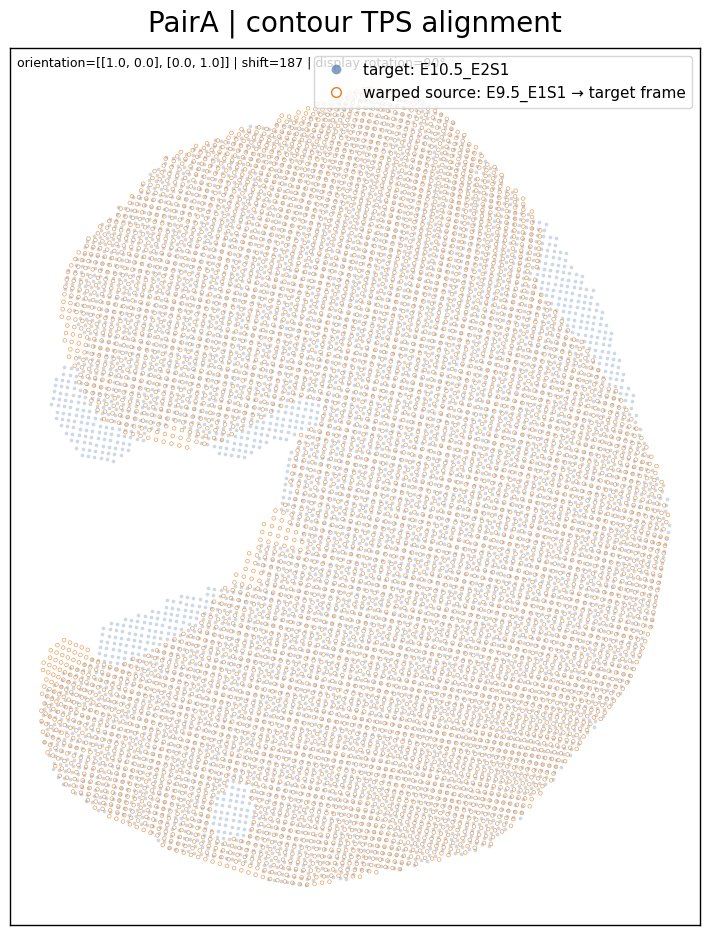

saved: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6/figures/PairA_src1_tgt0p6_02_tps_overlay.png

[2] INDEPENDENT NBVAE30 LEIDEN
source Leiden: 22 | target Leiden: 14

[3] TARGET LEIDEN -> LOCAL SPATIAL COMPONENTS
target median 1NN: 0.024984248524688647 | CC radius: 0.037476372787032974 | components: 386

[4] PARETO DOMAIN ROUTING + TOUCHED COMPONENTS
source domains: 22 | target domains: 14
Pareto-selected target domains per source: {'count': 22.0, 'mean': 2.1818181818181817, 'std': 1.0064725594803927, 'min': 1.0, '25%': 1.25, '50%': 2.0, '75%': 3.0, 'max': 4.0}

[5] POST-HOC SUPPORT EVALUATION


,pair,n_source_eval,support_fraction,weighted_coverage,macro_coverage,weighted_purity,macro_purity
0,PairA,5031,13.47%,72.27%,84.03%,12.70%,13.01%



[done] /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6


In [4]:
RUN_PAIR = "PairA"
PAIR_RESOLUTIONS = {
    "PairA": {"source": 1.0, "target": 0.6},
    "PairC": {"source": 1.0, "target": 0.6},
}
r = PAIR_RESOLUTIONS[RUN_PAIR]
RESULT = run_pair_from_scratch(RUN_PAIR, PAIR_CONFIG[RUN_PAIR], source_resolution=r["source"], target_resolution=r["target"])

PairC | E10.5_E2S1 -> E11.5_E1S1 | source res=1.0 | target res=0.6
output: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6
source: (8494, 2000) | target: (29972, 2000)

[1] CONTOUR ALIGNMENT
orientation: selected | chamfer: 0.01112380880488886
orientation matrix:
[[1. 0.]
 [0. 1.]]
cyclic shift: 170 | cyclic MSE: 0.012439785598434993
cycle error: median=0.081256 | q95=0.174519 (diagnostic only)


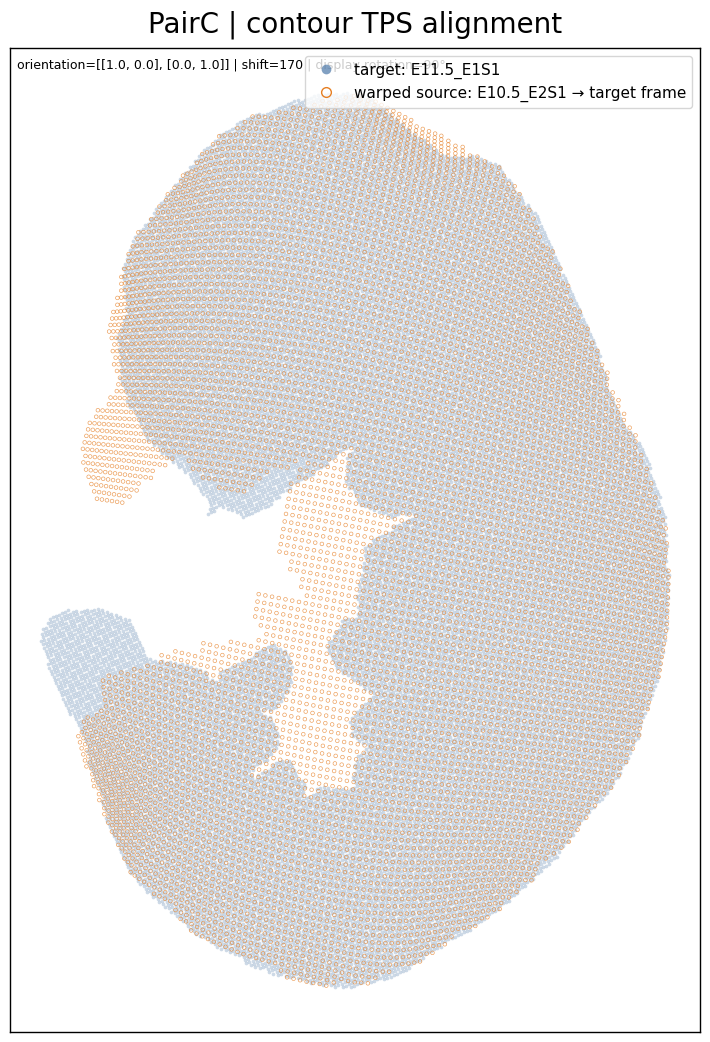

saved: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6/figures/PairC_src1_tgt0p6_02_tps_overlay.png

[2] INDEPENDENT NBVAE30 LEIDEN
source Leiden: 17 | target Leiden: 24

[3] TARGET LEIDEN -> LOCAL SPATIAL COMPONENTS
target median 1NN: 0.012270911310379468 | CC radius: 0.0184063669655692 | components: 649

[4] PARETO DOMAIN ROUTING + TOUCHED COMPONENTS
source domains: 17 | target domains: 24
Pareto-selected target domains per source: {'count': 17.0, 'mean': 2.588235294117647, 'std': 1.5434872662825796, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 4.0, 'max': 6.0}

[5] POST-HOC SUPPORT EVALUATION


,pair,n_source_eval,support_fraction,weighted_coverage,macro_coverage,weighted_purity,macro_purity
0,PairC,7081,11.88%,78.97%,84.01%,10.25%,11.63%



[done] /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6


In [5]:
RUN_PAIR = "PairC"
PAIR_RESOLUTIONS = {
    "PairA": {"source": 1.0, "target": 0.6},
    "PairC": {"source": 1.0, "target": 0.6},
}
r = PAIR_RESOLUTIONS[RUN_PAIR]
RESULT = run_pair_from_scratch(RUN_PAIR, PAIR_CONFIG[RUN_PAIR], source_resolution=r["source"], target_resolution=r["target"])

In [6]:
# ============================================================
# PARETO STAGE2 — ORIGINAL EXACT-HARD UNBALANCED FGW
# Helper cell only; nothing runs automatically.
# ============================================================

import os
GPU_ID = "0"   # edit before first JAX import if needed
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

from pathlib import Path
import gc, re, json, math, time, tempfile, importlib.util
import numpy as np
import pandas as pd
import anndata as ad
from IPython.display import display

import jax
import jax.numpy as jnp
from ott.geometry import pointcloud, costs
from ott.problems.quadratic import quadratic_problem
from moscot.backends.ott._utils import alpha_to_fused_penalty

# ============================================================
# CONFIG
# ============================================================

ROOT = Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/pareto")
CURATED_PATH = Path("/mnt/disk2/lirui/baseline_scripts/mosta_flatvi_fgw/MOSTA_curated_transitions.tsv")
DCR_SCRIPT = Path("/mnt/disk2/lirui/baseline_scripts/run_domain_concentration_fgw.py")

PAIR_CONFIG = {
    "PairA": {
        "source": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_source_E9.5_E1S1.h5ad"),
        "target": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_target_E10.5_E2S1.h5ad"),
    },
    "PairC": {
        "source": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E10.5_E2S1.nbvae30.h5ad"),
        "target": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E11.5_E1S1.nbvae30.h5ad"),
    },
}

FEATURE, SPATIAL, ANN = "X_nbvae_30", "spatial", "annotation"

ALPHA2 = 0.4
EPSILON = 1e-4
TAU_A, TAU_B = 1.0, 0.05

OUTER_MAX = 10
INNER_MIN, INNER_MAX = 20, 500
INNER_CHECK_EVERY, INNER_TOL = 10, 0.01

BATCH_SIZE = 1024
COST_CHUNK = 128


# ============================================================
# PATH / SUPPORT HELPERS
# ============================================================

def res_tag(x):
    return f"{float(x):g}".replace(".", "p")

def stage1_dir(pair_name, source_resolution, target_resolution):
    return ROOT / pair_name / f"src{res_tag(source_resolution)}_tgt{res_tag(target_resolution)}"

def resolve_support_path(run_dir):
    candidates = [
        run_dir / "hard_support.npz",
        run_dir / "feasible_set" / "hard_support.npz",
    ]
    for p in candidates:
        if p.exists(): return p
    hits = sorted(list(run_dir.glob("*hard_support*.npz")) + list((run_dir / "feasible_set").glob("*hard_support*.npz")) if (run_dir / "feasible_set").exists() else list(run_dir.glob("*hard_support*.npz")))
    if hits: return hits[0]
    raise FileNotFoundError(f"No hard-support npz found under {run_dir}")

def load_hard_support(path, ns, nt):
    S = np.load(path, allow_pickle=False)
    keys = set(S.files)

    # Current Stage1 format
    if {"source_domain_code", "support_indptr", "support_indices"} <= keys:
        codes = np.asarray(S["source_domain_code"], dtype=np.int32)
        indptr = np.asarray(S["support_indptr"], dtype=np.int64)
        indices = np.asarray(S["support_indices"], dtype=np.int32)

    # Earlier compact Stage1 format
    elif {"source_spot_leiden_code", "support_offsets", "support_target_indices"} <= keys:
        codes = np.asarray(S["source_spot_leiden_code"], dtype=np.int32)
        indptr = np.asarray(S["support_offsets"], dtype=np.int64)
        indices = np.asarray(S["support_target_indices"], dtype=np.int32)

    else:
        raise KeyError(f"Unknown hard-support format. keys={sorted(keys)}")

    n_domains = len(indptr) - 1
    if len(codes) != ns: raise ValueError(f"support source length={len(codes)} != ns={ns}")
    if codes.min() < 0 or codes.max() >= n_domains: raise ValueError("invalid source domain code")
    if len(indices) and (indices.min() < 0 or indices.max() >= nt): raise ValueError("invalid target index")

    sizes = np.diff(indptr)
    if np.any(sizes <= 0): raise RuntimeError("At least one source domain has empty support")

    return {"codes": codes, "indptr": indptr, "indices": indices, "n_domains": n_domains}


# ============================================================
# HARD SUPPORT -> SPARSE SPOT EDGES
# ============================================================

def build_stage2_edges(S, ns, nt):
    codes, indptr, indices = S["codes"], S["indptr"], S["indices"]
    domain_degree = np.diff(indptr)
    row_degree = domain_degree[codes]
    if np.any(row_degree <= 0): raise RuntimeError("empty feasible source row")

    row_offsets = np.zeros(ns + 1, dtype=np.int64)
    row_offsets[1:] = np.cumsum(row_degree)
    n_edges = int(row_offsets[-1])

    src_edge = np.repeat(np.arange(ns, dtype=np.int32), row_degree)
    tgt_edge = np.empty(n_edges, dtype=np.int32)

    for i in range(ns):
        d = int(codes[i])
        lo, hi = row_offsets[i], row_offsets[i + 1]
        tgt_edge[lo:hi] = indices[indptr[d]:indptr[d + 1]]

    return {
        "src_edge_np": src_edge, "tgt_edge_np": tgt_edge,
        "row_degree": row_degree, "row_offsets": row_offsets,
        "n_edges": n_edges, "density": n_edges / float(ns * nt),
    }


# ============================================================
# ORIGINAL NBVAE30 EXPRESSION COST
#
# Cexpr_ij = ||z_i-z_j||_2 / GLOBAL MAX over ALL i,j.
# Only allowed entries are retained afterwards.
# ============================================================

_DCR = None

def load_dcr_builder():
    global _DCR
    if _DCR is not None: return _DCR
    spec = importlib.util.spec_from_file_location("dcr_stage2_exact", DCR_SCRIPT)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    _DCR = mod
    return mod

def build_expression_edges(pair_name, zs, zt, E):
    dcr = load_dcr_builder()
    parent = "/mnt/disk2/lirui" if os.path.isdir("/mnt/disk2/lirui") else None

    with tempfile.TemporaryDirectory(prefix=f"_tmp_pareto_stage2_{pair_name}_", dir=parent) as tmp:
        c0_path = Path(tmp) / "C0.npy"
        C0, info = dcr.build_c0(c0_path, zs, zt, COST_CHUNK)
        expr = np.empty(E["n_edges"], dtype=np.float32)

        for i in range(zs.shape[0]):
            lo, hi = E["row_offsets"][i], E["row_offsets"][i + 1]
            expr[lo:hi] = C0[i, E["tgt_edge_np"][lo:hi]]
            if i == 0 or (i + 1) % 1000 == 0 or i == zs.shape[0] - 1:
                print(f"expression edges: {i+1}/{zs.shape[0]}")

        del C0
        gc.collect()

    return expr, info


# ============================================================
# ORIGINAL STAGE2 SPATIAL GEOMETRY
# dimension-wise standardization on RAW slice coordinates
# ============================================================

def standardize_spatial(x):
    x = np.asarray(x, dtype=np.float32)
    mu = x.mean(axis=0, keepdims=True)
    sd = x.std(axis=0, keepdims=True)
    sd = np.where(sd > 0, sd, 1.0)
    return ((x - mu) / sd).astype(np.float32)


# ============================================================
# EXACT SPARSE LOG-SINKHORN
# ============================================================

def make_sparse_solver(src_edge_np, tgt_edge_np, ns, nt):
    src_edge = jnp.asarray(src_edge_np, dtype=jnp.int32)
    tgt_edge = jnp.asarray(tgt_edge_np, dtype=jnp.int32)

    active_target_np = np.bincount(tgt_edge_np, minlength=nt) > 0
    active_target = jnp.asarray(active_target_np)

    loga = jnp.full((ns,), -jnp.log(float(ns)), dtype=jnp.float32)
    logb = jnp.full((nt,), -jnp.log(float(nt)), dtype=jnp.float32)

    def segment_lse(values, ids, n_segments):
        mx = jnp.full((n_segments,), -jnp.inf, dtype=values.dtype).at[ids].max(values)
        shifted = values - mx[ids]
        sm = jnp.zeros((n_segments,), dtype=values.dtype).at[ids].add(jnp.exp(shifted))
        return jnp.where(sm > 0, mx + jnp.log(sm), -jnp.inf)

    @jax.jit
    def sinkhorn_step(logK, logu, logv):
        row_lse = segment_lse(logK + logv[tgt_edge], src_edge, ns)
        new_logu = TAU_A * (loga - row_lse)

        col_lse = segment_lse(logK + new_logu[src_edge], tgt_edge, nt)
        proposed_v = TAU_B * (logb - col_lse)
        new_logv = jnp.where(active_target, proposed_v, 0.0)
        return new_logu, new_logv

    @jax.jit
    def source_error(logK, logu, logv):
        row_lse = segment_lse(logK + logv[tgt_edge], src_edge, ns)
        row_mass = jnp.exp(logu + row_lse)
        expected = 1.0 / ns
        return jnp.max(jnp.abs(row_mass - expected) / expected)

    def solve(edge_cost, epsilon):
        logK = -edge_cost / float(epsilon)
        logu = jnp.zeros(ns, dtype=jnp.float32)
        logv = jnp.zeros(nt, dtype=jnp.float32)
        final_err, used_iter = np.inf, INNER_MAX

        for it in range(1, INNER_MAX + 1):
            logu, logv = sinkhorn_step(logK, logu, logv)
            if it >= INNER_MIN and it % INNER_CHECK_EVERY == 0:
                final_err = float(jax.device_get(source_error(logK, logu, logv)))
                if final_err <= INNER_TOL:
                    used_iter = it
                    break

        edge_mass = jnp.exp(logu[src_edge] + logK + logv[tgt_edge])
        return edge_mass, used_iter, final_err

    return src_edge, tgt_edge, solve


# ============================================================
# OTT WRAPPER FOR GW LINEARIZATION
# ============================================================

class DenseTransport:
    def __init__(self, matrix):
        self.matrix = matrix

    def marginal(self, axis):
        return self.matrix.sum(axis=axis)


# ============================================================
# ORIGINAL STAGE2 CURATED EVALUATION
# self + curated descendants; Cavity IS NOT removed.
# ============================================================

def load_stage2_allowed():
    df = pd.read_csv(CURATED_PATH, sep=None, engine="python")

    def find_col(candidates):
        for c in candidates:
            if c in df.columns: return c
        raise KeyError(f"Cannot find columns {candidates}")

    src_col = find_col(["Cell_type", "cell_type", "source_annotation"])
    desc_col = find_col(["Known_descendants", "known_descendants", "descendants"])

    def split(x):
        x = str(x)
        if x.lower() == "nan": return []
        return [y.strip() for y in re.split(r"[,;|\n]+", x) if y.strip() and y.strip() != "/"]

    allowed = {}
    for _, r in df.iterrows():
        s = str(r[src_col]).strip()
        if not s or s.lower() == "nan": continue
        viable = set(split(r[desc_col]))
        viable.add(s)
        allowed[s] = viable

    return allowed


def evaluate_stage2(pair_name, source, target, E, edge_mass, allowed):
    src_ann = source.obs[ANN].astype(str).to_numpy()
    tgt_ann = target.obs[ANN].astype(str).to_numpy()
    ns = source.n_obs

    top1 = np.empty(ns, dtype=np.int32)
    top1_mass = np.empty(ns, dtype=np.float32)

    for i in range(ns):
        lo, hi = E["row_offsets"][i], E["row_offsets"][i + 1]
        local = edge_mass[lo:hi]
        k = int(np.argmax(local))
        top1[i] = E["tgt_edge_np"][lo + k]
        top1_mass[i] = local[k]

    endpoint_ann = tgt_ann[top1]
    top1_correct = np.asarray([
        endpoint_ann[i] in allowed.get(src_ann[i], {src_ann[i]})
        for i in range(ns)
    ], dtype=bool)

    rows = []
    for s in sorted(np.unique(src_ann)):
        ii = np.flatnonzero(src_ann == s)
        rows.append({
            "source_annotation": s,
            "n_source_cells": len(ii),
            "top1_accuracy": float(top1_correct[ii].mean()),
        })
    per_source = pd.DataFrame(rows)

    src_types = np.asarray(sorted(np.unique(src_ann)), dtype=str)
    tgt_types = np.asarray(sorted(np.unique(tgt_ann)), dtype=str)
    src_map = {x:i for i,x in enumerate(src_types)}
    tgt_map = {x:i for i,x in enumerate(tgt_types)}

    src_code = np.asarray([src_map[x] for x in src_ann], dtype=np.int32)
    tgt_code = np.asarray([tgt_map[x] for x in tgt_ann], dtype=np.int32)

    valid = np.zeros((len(src_types), len(tgt_types)), dtype=bool)
    for s, si in src_map.items():
        for t in allowed.get(s, {s}):
            if t in tgt_map: valid[si, tgt_map[t]] = True

    edge_correct = valid[src_code[E["src_edge_np"]], tgt_code[E["tgt_edge_np"]]]

    total_mass = float(edge_mass.sum(dtype=np.float64))
    correct_mass = float(edge_mass[edge_correct].sum(dtype=np.float64))
    mass_total = np.bincount(src_code[E["src_edge_np"]], weights=edge_mass, minlength=len(src_types))
    mass_correct = np.bincount(src_code[E["src_edge_np"]], weights=edge_mass * edge_correct, minlength=len(src_types))
    mass_acc = np.divide(mass_correct, mass_total, out=np.full(len(src_types), np.nan), where=mass_total > 0)

    per_source = per_source.merge(
        pd.DataFrame({"source_annotation": src_types, "transport_mass_accuracy": mass_acc}),
        on="source_annotation", how="left"
    )

    details = pd.DataFrame({
        "source_index": np.arange(ns),
        "source_obs_name": source.obs_names.astype(str),
        "source_annotation": src_ann,
        "target_index_top1": top1,
        "target_obs_name_top1": target.obs_names.astype(str).to_numpy()[top1],
        "target_annotation_top1": endpoint_ann,
        "top1_mass": top1_mass,
        "top1_correct": top1_correct,
    })

    summary = {
        "pair": pair_name,
        "top1_weighted": float(top1_correct.mean()),
        "top1_macro": float(per_source["top1_accuracy"].mean()),
        "mass_weighted": correct_mass / total_mass,
        "mass_macro": float(np.nanmean(mass_acc)),
        "transport_mass": total_mass,
        "n_allowed_edges": int(E["n_edges"]),
        "support_density": float(E["density"]),
        "forbidden_mass": 0.0,
    }

    return summary, per_source, details, top1


# ============================================================
# SAVE
# ============================================================

def save_stage2(stage2_dir, prefix, support_path, E, edge_mass, history, summary, per_source, details, top1, fused_penalty):
    stage2_dir.mkdir(parents=True, exist_ok=True)

    # Compact sparse coupling:
    # row i = targets[row_offsets[i]:row_offsets[i+1]]
    np.savez_compressed(
        stage2_dir / f"{prefix}_transport_sparse.npz",
        row_offsets=E["row_offsets"],
        target_indices=E["tgt_edge_np"],
        mass=edge_mass.astype(np.float32),
    )

    np.save(stage2_dir / f"{prefix}_top1_target_index.npy", top1)
    history.to_csv(stage2_dir / f"{prefix}_iteration_history.csv", index=False)
    per_source.to_csv(stage2_dir / f"{prefix}_by_annotation.csv", index=False)
    details.to_csv(stage2_dir / f"{prefix}_top1_details.csv", index=False)
    pd.DataFrame([summary]).to_csv(stage2_dir / f"{prefix}_summary.csv", index=False)

    config = {
        "alpha2": ALPHA2,
        "fused_penalty": float(fused_penalty),
        "epsilon": EPSILON,
        "tau_a": TAU_A,
        "tau_b": TAU_B,
        "outer_iterations": OUTER_MAX,
        "inner_min": INNER_MIN,
        "inner_max": INNER_MAX,
        "inner_check_every": INNER_CHECK_EVERY,
        "inner_source_tol": INNER_TOL,
        "spatial": "raw spatial -> dimension-wise standardization -> Euclidean -> max_cost",
        "expression": "NBVAE30 Euclidean / GLOBAL source-target maximum",
        "support": str(support_path),
        "hard_support": True,
        "forbidden_edges_enter_sinkhorn": False,
        "stage1_tps_used_in_stage2_objective": False,
        "stage1_pareto_scores_used_in_stage2_objective": False,
        "annotation_used_in_optimization": False,
        "curated_used_in_optimization": False,
        "cavity_excluded_from_stage2_evaluation": False,
    }
    with open(stage2_dir / f"{prefix}_config.json", "w") as f:
        json.dump(config, f, indent=2)


# ============================================================
# RUN ONE PAIR
# ============================================================

def run_stage2_pair(pair_name, source_resolution=1.0, target_resolution=0.6):
    if jax.default_backend() != "gpu":
        raise RuntimeError(
            f"JAX backend={jax.default_backend()}, expected GPU. "
            "If JAX was already imported before CUDA_VISIBLE_DEVICES was set, restart the kernel."
        )

    cfg = PAIR_CONFIG[pair_name]
    run_dir = stage1_dir(pair_name, source_resolution, target_resolution)
    support_path = resolve_support_path(run_dir)
    stage2_dir = run_dir / "stage2"
    tag = f"src{res_tag(source_resolution)}_tgt{res_tag(target_resolution)}"
    prefix = f"{pair_name}_{tag}_stage2"

    print("\n" + "="*110)
    print(f"{pair_name} | EXACT-HARD STAGE2 FGW")
    print("stage1:", run_dir)
    print("support:", support_path)
    print("output :", stage2_dir)
    print("="*110)

    source, target = ad.read_h5ad(cfg["source"]), ad.read_h5ad(cfg["target"])
    zs = np.asarray(source.obsm[FEATURE], dtype=np.float32)
    zt = np.asarray(target.obsm[FEATURE], dtype=np.float32)
    ss = np.asarray(source.obsm[SPATIAL], dtype=np.float32)
    st = np.asarray(target.obsm[SPATIAL], dtype=np.float32)
    ns, nt = source.n_obs, target.n_obs

    # --------------------------------------------------------
    # 1. HARD SUPPORT
    # --------------------------------------------------------
    S = load_hard_support(support_path, ns, nt)
    E = build_stage2_edges(S, ns, nt)

    print("\n[1] EXACT HARD SUPPORT")
    print(f"source={ns:,} | target={nt:,} | source domains={S['n_domains']}")
    print(f"allowed edges={E['n_edges']:,} / {ns*nt:,}")
    print(f"support density={E['density']:.3%}")
    print(f"median targets/source={np.median(E['row_degree']):,.0f}")
    print(f"min/max targets/source={E['row_degree'].min():,}/{E['row_degree'].max():,}")

    # --------------------------------------------------------
    # 2. EXPRESSION LINEAR COST
    # --------------------------------------------------------
    print("\n[2] ORIGINAL EXPRESSION COST")
    expr_edge_np, c0_info = build_expression_edges(pair_name, zs, zt, E)
    print(c0_info)
    print("allowed-edge expression range:", float(expr_edge_np.min()), "->", float(expr_edge_np.max()))

    # --------------------------------------------------------
    # 3. RAW WITHIN-SLICE SPATIAL GW GEOMETRIES
    # --------------------------------------------------------
    print("\n[3] RAW SPATIAL GW GEOMETRIES")
    ss_std, st_std = standardize_spatial(ss), standardize_spatial(st)
    euclidean = costs.Euclidean()

    geom_xx = pointcloud.PointCloud(
        jnp.asarray(ss_std), cost_fn=euclidean,
        batch_size=BATCH_SIZE, scale_cost="max_cost"
    )
    geom_yy = pointcloud.PointCloud(
        jnp.asarray(st_std), cost_fn=euclidean,
        batch_size=BATCH_SIZE, scale_cost="max_cost"
    )

    a = jnp.ones(ns, dtype=jnp.float32) / ns
    b = jnp.ones(nt, dtype=jnp.float32) / nt

    qprob = quadratic_problem.QuadraticProblem(
        geom_xx=geom_xx, geom_yy=geom_yy, geom_xy=None,
        a=a, b=b, loss="sqeucl",
        tau_a=TAU_A, tau_b=TAU_B,
        gw_unbalanced_correction=True, ranks=-1
    )

    fused_penalty = float(alpha_to_fused_penalty(ALPHA2))
    print(f"alpha2={ALPHA2} | fused penalty={fused_penalty}")
    print(f"epsilon={EPSILON} | tau=({TAU_A},{TAU_B}) | outer={OUTER_MAX}")

    # --------------------------------------------------------
    # 4. SPARSE SOLVER + INITIAL COUPLING
    # --------------------------------------------------------
    print("\n[4] INITIAL HARD-FEASIBLE COUPLING")
    src_edge, tgt_edge, solve_sparse_ot = make_sparse_solver(
        E["src_edge_np"], E["tgt_edge_np"], ns, nt
    )
    expr_edge = jnp.asarray(expr_edge_np, dtype=jnp.float32)

    edge_mass = jnp.asarray(
        ((1.0 / ns) / E["row_degree"][E["src_edge_np"]]).astype(np.float32)
    )

    P = (
        jnp.zeros((ns, nt), dtype=jnp.float32)
        .at[src_edge, tgt_edge]
        .set(edge_mass)
    )

    print("initial transport mass =", float(jax.device_get(P.sum())))

    # --------------------------------------------------------
    # 5. ORIGINAL OUTER GW LINEARIZATION
    # --------------------------------------------------------
    print("\n[5] EXACT-HARD FGW")
    history = []
    old_transport_mass = float(jax.device_get(qprob.init_transport_mass()))
    t_all = time.time()

    for outer in range(1, OUTER_MAX + 1):
        t0 = time.time()
        current_mass = float(jax.device_get(P.sum()))
        rescale_factor = math.sqrt(old_transport_mass / current_mass)

        # Pure GW + unbalanced correction linearization.
        # Expression is NOT inside qprob.
        lin_prob = qprob.update_linearization(
            DenseTransport(P),
            epsilon=EPSILON,
            old_transport_mass=old_transport_mass
        )

        # Only allowed edges are retained.
        gw_edge_cost = lin_prob.geom.cost_matrix[src_edge, tgt_edge]

        # Exact original FGW local linearized cost.
        edge_cost = gw_edge_cost + fused_penalty * rescale_factor * expr_edge
        eps_eff = float(jax.device_get(lin_prob.geom.epsilon))

        edge_mass, inner_iter, inner_err = solve_sparse_ot(edge_cost, eps_eff)

        # Forbidden entries remain exactly zero.
        P_new = (
            jnp.zeros((ns, nt), dtype=jnp.float32)
            .at[src_edge, tgt_edge]
            .set(edge_mass)
        )

        new_mass = float(jax.device_get(P_new.sum()))
        history.append({
            "outer": outer,
            "transport_mass": new_mass,
            "inner_iterations": inner_iter,
            "inner_source_rel_error": inner_err,
            "epsilon_effective": eps_eff,
            "rescale_factor": rescale_factor,
            "seconds": time.time() - t0,
        })

        print(
            f"outer {outer:02d}/{OUTER_MAX} | mass={new_mass:.6g} | "
            f"inner={inner_iter:3d} | src_err={inner_err:.3e} | "
            f"eps={eps_eff:.3e} | rescale={rescale_factor:.6f} | "
            f"{history[-1]['seconds']:.1f}s",
            flush=True
        )

        # Same original OTT mass bookkeeping.
        old_transport_mass = current_mass
        P = P_new

        del lin_prob, gw_edge_cost, edge_cost, P_new
        gc.collect()

    runtime = time.time() - t_all
    history_df = pd.DataFrame(history)

    # --------------------------------------------------------
    # 6. HARD-SUPPORT SANITY
    # --------------------------------------------------------
    print("\n[6] HARD-SUPPORT SANITY")

    first_forbidden = {}
    for d in range(S["n_domains"]):
        allowed = np.zeros(nt, dtype=bool)
        allowed[S["indices"][S["indptr"][d]:S["indptr"][d+1]]] = True
        bad = np.flatnonzero(~allowed)
        first_forbidden[d] = int(bad[0]) if len(bad) else None

    fi, fj = [], []
    for i in range(ns):
        j = first_forbidden[int(S["codes"][i])]
        if j is not None:
            fi.append(i); fj.append(j)

    if fi:
        sampled_forbidden = np.asarray(jax.device_get(
            P[jnp.asarray(fi, dtype=jnp.int32), jnp.asarray(fj, dtype=jnp.int32)]
        ))
    else:
        sampled_forbidden = np.asarray([], dtype=np.float32)

    row_mass = np.asarray(jax.device_get(P.sum(axis=1)))
    print("max sampled forbidden mass =", float(sampled_forbidden.max(initial=0)))
    print("nonzero sampled forbidden =", int(np.count_nonzero(sampled_forbidden)))
    print("zero source rows =", int(np.sum(row_mass <= 0)))

    assert np.count_nonzero(sampled_forbidden) == 0
    assert np.all(row_mass > 0)

    # --------------------------------------------------------
    # 7. CPU FINAL SPARSE MASS + POST-HOC EVALUATION
    # --------------------------------------------------------
    edge_mass_np = np.asarray(jax.device_get(edge_mass), dtype=np.float32)
    if not np.isfinite(edge_mass_np).all() or np.any(edge_mass_np < 0):
        raise RuntimeError("invalid final edge mass")

    print("\n[7] POST-HOC CURATED EVALUATION — Cavity INCLUDED")
    allowed = load_stage2_allowed()
    summary, per_source, details, top1 = evaluate_stage2(
        pair_name, source, target, E, edge_mass_np, allowed
    )
    summary["runtime_seconds"] = runtime

    display(pd.DataFrame([summary]).style.format({
        "top1_weighted":"{:.2%}", "top1_macro":"{:.2%}",
        "mass_weighted":"{:.2%}", "mass_macro":"{:.2%}",
        "support_density":"{:.2%}", "transport_mass":"{:.6f}",
        "forbidden_mass":"{:.1e}", "runtime_seconds":"{:.1f}",
    }))

    # --------------------------------------------------------
    # 8. SAVE
    # --------------------------------------------------------
    save_stage2(
        stage2_dir=stage2_dir, prefix=prefix, support_path=support_path,
        E=E, edge_mass=edge_mass_np, history=history_df,
        summary=summary, per_source=per_source,
        details=details, top1=top1,
        fused_penalty=fused_penalty
    )

    print(f"\n[DONE] {stage2_dir}")

    # free large GPU objects before next pair
    del P, edge_mass, expr_edge, geom_xx, geom_yy, qprob
    gc.collect()
    try: jax.clear_caches()
    except Exception: pass

    return {
        "summary": summary,
        "per_source": per_source,
        "history": history_df,
        "stage2_dir": stage2_dir,
    }

In [7]:
# ============================================================
# RUN STAGE2
# ============================================================

STAGE2_RESULTS = {}

PAIR_RESOLUTIONS = {
    "PairA": (1.0, 0.6),
    "PairC": (1.0, 0.6),
}

for pair_name in ["PairA", "PairC"]:
    sr, tr = PAIR_RESOLUTIONS[pair_name]
    STAGE2_RESULTS[pair_name] = run_stage2_pair(
        pair_name,
        source_resolution=sr,
        target_resolution=tr,
    )

STAGE2_SUMMARY = pd.DataFrame([
    STAGE2_RESULTS[p]["summary"]
    for p in ["PairA", "PairC"]
])

display(
    STAGE2_SUMMARY.style.format({
        "top1_weighted":"{:.2%}", "top1_macro":"{:.2%}",
        "mass_weighted":"{:.2%}", "mass_macro":"{:.2%}",
        "support_density":"{:.2%}", "transport_mass":"{:.6f}",
        "forbidden_mass":"{:.1e}", "runtime_seconds":"{:.1f}",
    })
)


PairA | EXACT-HARD STAGE2 FGW
stage1: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6
support: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6/hard_support.npz
output : /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6/stage2

[1] EXACT HARD SUPPORT
source=5,870 | target=8,494 | source domains=22
allowed edges=6,754,212 / 49,859,780
support density=13.546%
median targets/source=949
min/max targets/source=144/2,381

[2] ORIGINAL EXPRESSION COST
[cost] rows 0:128/5870
[cost] rows 1024:1152/5870
[cost] rows 2048:2176/5870
[cost] rows 3072:3200/5870
[cost] rows 4096:4224/5870
[cost] rows 5120:5248/5870
[cost] rows 5760:5870/5870
[cost] C0 normalized: min=0.174865, max=1.000000
expression edges: 1/5870
expression edges: 1000/5870
expression edges: 2000/5870
expression edges: 3000/5870
expression edges: 4000/5870
expression edges: 5000/5870
expression edges: 5870/5870
{'shape': [5870, 8494], 'raw_min': 3.3894143104553223, 'raw_max': 

,pair,top1_weighted,top1_macro,mass_weighted,mass_macro,transport_mass,n_allowed_edges,support_density,forbidden_mass,runtime_seconds
0,PairA,49.42%,48.72%,49.42%,48.72%,0.999916,6754212,13.55%,0.0e+00,19.3



[DONE] /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6/stage2

PairC | EXACT-HARD STAGE2 FGW
stage1: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6
support: /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6/hard_support.npz
output : /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6/stage2

[1] EXACT HARD SUPPORT
source=8,494 | target=29,972 | source domains=17
allowed edges=28,672,858 / 254,582,168
support density=11.263%
median targets/source=2,806
min/max targets/source=1,381/6,278

[2] ORIGINAL EXPRESSION COST
[cost] rows 0:128/8494
[cost] rows 1024:1152/8494
[cost] rows 2048:2176/8494
[cost] rows 3072:3200/8494
[cost] rows 4096:4224/8494
[cost] rows 5120:5248/8494
[cost] rows 6144:6272/8494
[cost] rows 7168:7296/8494
[cost] rows 8192:8320/8494
[cost] rows 8448:8494/8494
[cost] C0 normalized: min=0.204235, max=1.000000
expression edges: 1/8494
expression edges: 1000/8494
expression edges: 2000/8494
express

,pair,top1_weighted,top1_macro,mass_weighted,mass_macro,transport_mass,n_allowed_edges,support_density,forbidden_mass,runtime_seconds
0,PairC,38.44%,42.75%,38.43%,42.74%,1.000221,28672858,11.26%,0.0e+00,35.7



[DONE] /mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6/stage2


,pair,top1_weighted,top1_macro,mass_weighted,mass_macro,transport_mass,n_allowed_edges,support_density,forbidden_mass,runtime_seconds
0,PairA,49.42%,48.72%,49.42%,48.72%,0.999916,6754212,13.55%,0.0e+00,19.3
1,PairC,38.44%,42.75%,38.43%,42.74%,1.000221,28672858,11.26%,0.0e+00,35.7
